# Pharmaceutical Compound Comparison Using the Chempirical API

**API:** [Chempirical](https://chempirical.com/api/)

## Objective

This notebook uses Python to retrieve chemical property data for five common pharmaceutical compounds from the Chempirical API. The retrieved data are organized into a comparison table and visualized using a bar chart to identify differences in molar mass.

**Compounds analyzed:**
- Aspirin
- Acetaminophen
- Ibuprofen
- Naproxen
- Caffeine

In [1]:
import requests
import time

# Dictionary of pharmaceutical compounds and CAS numbers
compounds = {
    "Aspirin": "50-78-2",
    "Acetaminophen": "103-90-2",
    "Ibuprofen": "15687-27-1",
    "Naproxen": "22204-53-1",
    "Caffeine": "58-08-2"
}

# Store retrieved compound info
compound_data = []

# Retrieve info for each compound
for name, cas in compounds.items():

    url = f"https://chempirical.com/api/molecules/{cas}"

    response = requests.get(url, timeout=15)
    response.raise_for_status()

    data = response.json()

    # Extract selected chemical properties
    compound_info = {
        "Name": data.get("name", name),
        "Formula": data.get("formula"),
        "Molar Mass (g/mol)": data.get(
            "properties", {}
        ).get("molar_mass_g_per_mol")
    }

    compound_data.append(compound_info)

    print(f"Retrieved data for {name}")

    # Prevent requests from being sent too quickly
    time.sleep(0.5)

print("\nAll compound data has been retrieved!")

Retrieved data for Aspirin
Retrieved data for Acetaminophen
Retrieved data for Ibuprofen
Retrieved data for Naproxen
Retrieved data for Caffeine

All compound data has been retrieved!


In [2]:
import pandas as pd

# Convert list of dictionaries into DataFrame
df = pd.DataFrame(compound_data)

# Sort by molar mass (highest to lowest)
df = df.sort_values(
    by="Molar Mass (g/mol)",
    ascending=False
)

# Reset row index
df = df.reset_index(drop=True)
df.index = df.index + 1

# Display table
display(df)

,Name,Formula,Molar Mass (g/mol)
1,Naproxen,C14H14O3,230.263
2,Ibuprofen,C13H18O2,206.285
3,Caffeine,C8H10N4O2,194.194
4,Aspirin,C9H8O4,180.159
5,Acetaminophen,C8H9NO2,151.165


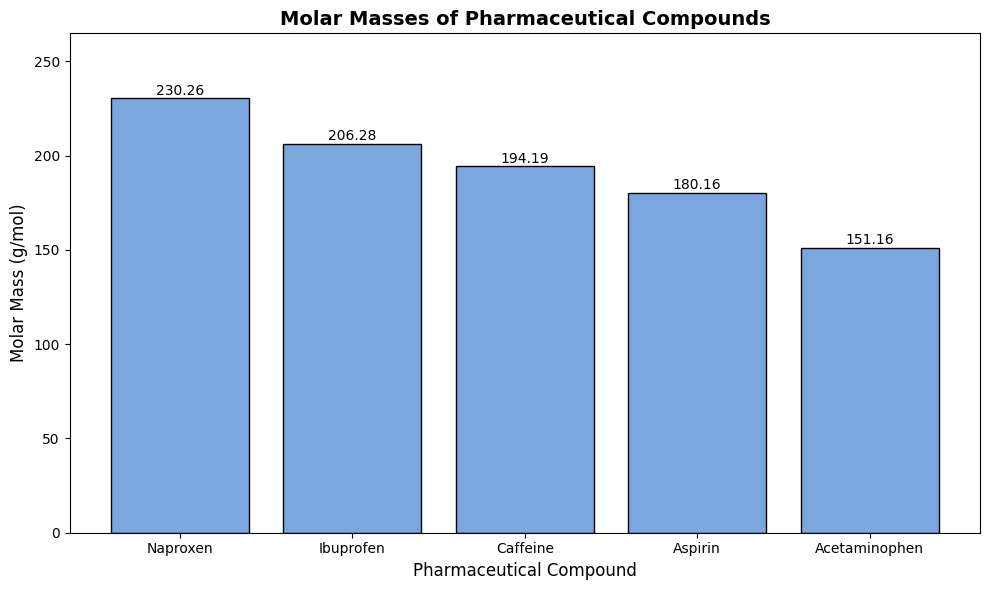

In [3]:
import matplotlib.pyplot as plt

# Create a figure
plt.figure(figsize=(10, 6))

# Plot molar mass for each compound
bars = plt.bar(
    df["Name"],
    df["Molar Mass (g/mol)"],
    color="#7BA6DE",
    edgecolor="black"
)

# Add labels and title
plt.title(
    "Molar Masses of Pharmaceutical Compounds",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Pharmaceutical Compound", fontsize=12)
plt.ylabel("Molar Mass (g/mol)", fontsize=12)

# Display values above each bar
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 2,
        f"{height:.2f}",
        ha="center",
        fontsize=10
    )

# Adjust layout and display
plt.ylim(0, df["Molar Mass (g/mol)"].max() * 1.15)
plt.tight_layout()
plt.show()

In [4]:
# Identify compounds with highest and lowest molar masses
highest = df.loc[df["Molar Mass (g/mol)"].idxmax()]
lowest = df.loc[df["Molar Mass (g/mol)"].idxmin()]

# Calculate the difference
difference = (
    highest["Molar Mass (g/mol)"]
    - lowest["Molar Mass (g/mol)"]
)

print(f"Highest molar mass: {highest['Name']} "
      f"({highest['Molar Mass (g/mol)']:.3f} g/mol)")

print(f"Lowest molar mass: {lowest['Name']} "
      f"({lowest['Molar Mass (g/mol)']:.3f} g/mol)")

print(f"Difference: {difference:.3f} g/mol")

Highest molar mass: Naproxen (230.263 g/mol)
Lowest molar mass: Acetaminophen (151.165 g/mol)
Difference: 79.098 g/mol


## Conclusion

The Chempirical API successfully retrieved chemical formulas and molar masses for five pharmaceutical compounds: aspirin, acetaminophen, ibuprofen, naproxen, and caffeine.

Among the five compounds, **naproxen had the highest molar mass (230.263 g/mol)**, while **acetaminophen had the lowest (151.165 g/mol)**. The difference between their molar masses was **79.098 g/mol**.

Using pandas, the retrieved data were organized and sorted by molar mass in descending order. Matplotlib was then used to create a bar chart comparing the compounds.

This analysis demonstrates how Python can interact with an external API to retrieve, process, analyze, and visualize chemical data.